<a href="https://colab.research.google.com/github/shubhmittal-627/ShubhMittal-Cognitive-Computing-UCS420-/blob/main/assignment(8).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install -q textblob wordcloud

import re, nltk
import pandas as pd
import matplotlib.pyplot as plt

for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4"]:
    nltk.download(pkg, quiet=True)

from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer

stop_words = set(stopwords.words("english"))

ques1

Cleaned:
 technology has completely changed the way i learn and solve problems when i am stuck on a bug i can search forums read documentation or ask an ai assistant within seconds machine learning fascinates me because computers can discover patterns that humans would never notice i love building small projects like a hospital queue system because they turn theory into something real however technology also demands responsibility since poorly designed software can affect thousands of people i believe the best developers are curious patient and always willing to keep learning
Number of sentences: 6
- Technology has completely changed the way I learn and solve problems.
- When I am stuck on a bug, I can search forums, read documentation, or ask an AI assistant within seconds.
- Machine learning fascinates me because computers can discover patterns that humans would never notice.
- I love building small projects, like a hospital queue system, because they turn theory into something real.

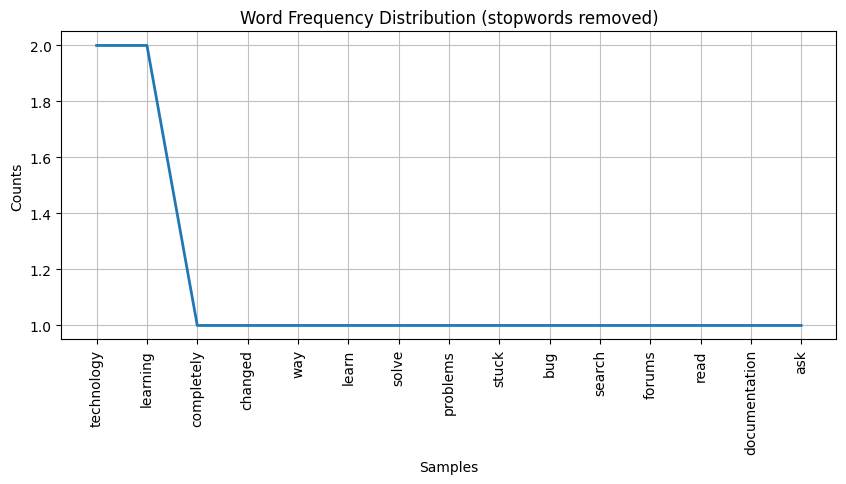

In [2]:
paragraph = (
    "Technology has completely changed the way I learn and solve problems. "
    "When I am stuck on a bug, I can search forums, read documentation, or ask an AI assistant within seconds. "
    "Machine learning fascinates me because computers can discover patterns that humans would never notice. "
    "I love building small projects, like a hospital queue system, because they turn theory into something real. "
    "However, technology also demands responsibility, since poorly designed software can affect thousands of people. "
    "I believe the best developers are curious, patient, and always willing to keep learning."
)

# 1.
clean = re.sub(r"[^\w\s]", "", paragraph.lower())
print("Cleaned:\n", clean)

# 2.
sentences = sent_tokenize(paragraph)
print("Number of sentences:", len(sentences))
for s in sentences:
    print("-", s)

words = word_tokenize(clean)
print("\nWords:", words)

# 3.
text = paragraph.lower()
split_tokens = text.split()
nltk_tokens = word_tokenize(text)

print("split() count        :", len(split_tokens))
print("word_tokenize count  :", len(nltk_tokens))
print("split() sample       :", split_tokens[:12])
print("word_tokenize sample :", nltk_tokens[:12])

# 4.
filtered = [w for w in words if w not in stop_words]
print(filtered)

# 5.
freq = nltk.FreqDist(filtered)
print(freq.most_common(10))

plt.figure(figsize=(10, 4))
freq.plot(15, title="Word Frequency Distribution (stopwords removed)")
plt.show()

ques 2

In [3]:
# 1.
alpha_words = re.findall(r"\b[a-zA-Z]+\b", paragraph.lower())

# 2.
no_stop = [w for w in alpha_words if w not in stop_words]

# 3.
stemmer = PorterStemmer()
stemmed = [stemmer.stem(w) for w in no_stop]

# 4.
lemmatizer = WordNetLemmatizer()
lemma_noun = [lemmatizer.lemmatize(w) for w in no_stop]
lemma_verb = [lemmatizer.lemmatize(w, pos="v") for w in no_stop]

print("Stemmed   :", stemmed)
print("Lemmatized:", lemma_noun)

# 5.
df = pd.DataFrame({"word": no_stop, "stem": stemmed,
                   "lemma (noun)": lemma_noun, "lemma (verb)": lemma_verb})
df[(df.word != df.stem) | (df.word != df["lemma (noun)"]) | (df.word != df["lemma (verb)"])].drop_duplicates()

Stemmed   : ['technolog', 'complet', 'chang', 'way', 'learn', 'solv', 'problem', 'stuck', 'bug', 'search', 'forum', 'read', 'document', 'ask', 'ai', 'assist', 'within', 'second', 'machin', 'learn', 'fascin', 'comput', 'discov', 'pattern', 'human', 'would', 'never', 'notic', 'love', 'build', 'small', 'project', 'like', 'hospit', 'queue', 'system', 'turn', 'theori', 'someth', 'real', 'howev', 'technolog', 'also', 'demand', 'respons', 'sinc', 'poorli', 'design', 'softwar', 'affect', 'thousand', 'peopl', 'believ', 'best', 'develop', 'curiou', 'patient', 'alway', 'will', 'keep', 'learn']
Lemmatized: ['technology', 'completely', 'changed', 'way', 'learn', 'solve', 'problem', 'stuck', 'bug', 'search', 'forum', 'read', 'documentation', 'ask', 'ai', 'assistant', 'within', 'second', 'machine', 'learning', 'fascinates', 'computer', 'discover', 'pattern', 'human', 'would', 'never', 'notice', 'love', 'building', 'small', 'project', 'like', 'hospital', 'queue', 'system', 'turn', 'theory', 'something

,word,stem,lemma (noun),lemma (verb)
0,technology,technolog,technology,technology
1,completely,complet,completely,completely
2,changed,chang,changed,change
5,solve,solv,solve,solve
6,problems,problem,problem,problems
7,stuck,stuck,stuck,stick
10,forums,forum,forum,forums
12,documentation,document,documentation,documentation
15,assistant,assist,assistant,assistant
17,seconds,second,second,second


ques 3

In [4]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

texts = [
    "India won the cricket world cup. The cricket final against Australia was thrilling, and every cricket fan celebrated the win.",
    "The new smartphone has an amazing camera. The camera takes sharp photos and the battery lasts a long time, so users love the smartphone.",
    "Heavy rainfall caused flooding in several cities. The flooding disrupted train services and rainfall warnings were issued for the new week.",
]
idx = ["Text1", "Text2", "Text3"]

# 1.
cv = CountVectorizer(stop_words="english")
bow = cv.fit_transform(texts)
bow_df = pd.DataFrame(bow.toarray(), columns=cv.get_feature_names_out(), index=idx)
bow_df.T

# 2.
tv = TfidfVectorizer(stop_words="english")
tfidf = tv.fit_transform(texts)
tfidf_df = pd.DataFrame(tfidf.toarray(), columns=tv.get_feature_names_out(), index=idx)
tfidf_df.round(3).T

# 3.
for name, row in tfidf_df.iterrows():
    top3 = row.sort_values(ascending=False).head(3)
    print(name, "->", ", ".join(f"{w} ({s:.3f})" for w, s in top3.items()))

Text1 -> cricket (0.688), celebrated (0.229), australia (0.229)
Text2 -> camera (0.464), smartphone (0.464), amazing (0.232)
Text3 -> flooding (0.477), rainfall (0.477), disrupted (0.239)


ques 4


In [6]:
from sklearn.metrics.pairwise import cosine_similarity

ai_text = ("Artificial intelligence enables machines to learn from data and make decisions. "
           "Machine learning models are trained on large datasets to recognize patterns. "
           "AI powers applications like chatbots, recommendation systems and self driving cars. "
           "It improves automatically as it processes more data.")

bc_text = ("Blockchain is a distributed ledger that records transactions across many computers. "
           "Each block is linked to the previous one using cryptographic hashes. "
           "Once data is recorded it cannot be changed, which makes the system secure and transparent. "
           "It powers cryptocurrencies and applications like smart contracts.")

# 1.
def preprocess(text):
    text = re.sub(r"[^\w\s]", "", text.lower())
    return [t for t in word_tokenize(text) if t not in stop_words]

t1, t2 = preprocess(ai_text), preprocess(bc_text)
print(t1, "\n", t2)

# 2a.
s1, s2 = set(t1), set(t2)
jaccard = len(s1 & s2) / len(s1 | s2)
print("Common words:", s1 & s2)
print(f"Jaccard similarity: {jaccard:.3f}")

# 2b.
mat = TfidfVectorizer(stop_words="english").fit_transform([ai_text, bc_text])
cos = cosine_similarity(mat[0], mat[1])[0][0]
print(f"Cosine similarity: {cos:.3f}")

['artificial', 'intelligence', 'enables', 'machines', 'learn', 'data', 'make', 'decisions', 'machine', 'learning', 'models', 'trained', 'large', 'datasets', 'recognize', 'patterns', 'ai', 'powers', 'applications', 'like', 'chatbots', 'recommendation', 'systems', 'self', 'driving', 'cars', 'improves', 'automatically', 'processes', 'data'] 
 ['blockchain', 'distributed', 'ledger', 'records', 'transactions', 'across', 'many', 'computers', 'block', 'linked', 'previous', 'one', 'using', 'cryptographic', 'hashes', 'data', 'recorded', 'changed', 'makes', 'system', 'secure', 'transparent', 'powers', 'cryptocurrencies', 'applications', 'like', 'smart', 'contracts']
Common words: {'like', 'applications', 'data', 'powers'}
Jaccard similarity: 0.075
Cosine similarity: 0.101


ques 5

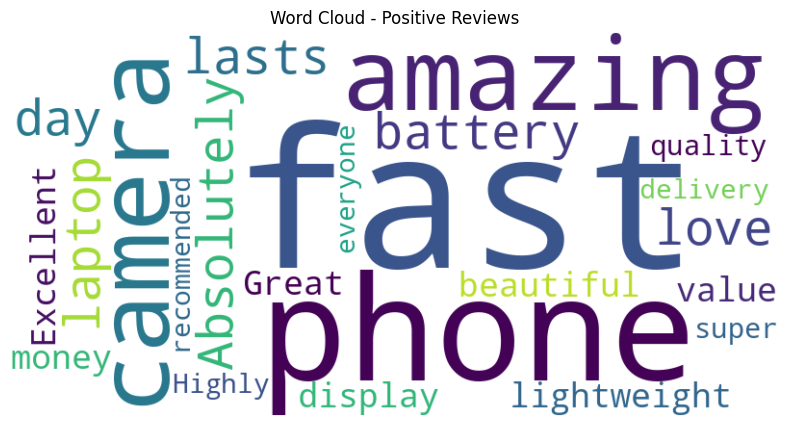

In [7]:
from textblob import TextBlob
from wordcloud import WordCloud

reviews = [
    "The phone has an amazing camera and the battery lasts all day. Absolutely love it!",
    "Terrible customer service. The delivery was late and the product arrived damaged.",
    "The laptop is fast, lightweight and the display is beautiful. Great value for money.",
    "The product arrived on Tuesday. It comes in a standard box with a user manual.",
    "Worst purchase ever. The app keeps crashing and support never replied.",
    "Excellent quality and super fast delivery. Highly recommended to everyone!",
]

#
def classify(p):
    if p > 0.1:  return "Positive"
    if p < -0.1: return "Negative"
    return "Neutral"

rows = []
for r in reviews:
    s = TextBlob(r).sentiment
    rows.append({"Review": r, "Polarity": round(s.polarity, 3),
                 "Subjectivity": round(s.subjectivity, 3),
                 "Sentiment": classify(s.polarity)})

df = pd.DataFrame(rows)
df

# 3.
pos_text = " ".join(df[df.Sentiment == "Positive"]["Review"])
wc = WordCloud(width=800, height=400, background_color="white",
               stopwords=stop_words).generate(pos_text)

plt.figure(figsize=(10, 5))
plt.imshow(wc, interpolation="bilinear")
plt.axis("off")
plt.title("Word Cloud - Positive Reviews")
plt.show()